# Part 0 - Mini project - Movie recommendation system

### Download MovieLens 100K dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import kagglehub

In [2]:
path = kagglehub.dataset_download("abhikjha/movielens-100k")

print("Path to dataset files:", path)

100%|██████████| 971k/971k [00:00<00:00, 52.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/abhikjha/movielens-100k/versions/1


## Present README contents

In [ ]:
path = path + "/ml-latest-small/"
with open(path + "README.txt", 'r', encoding='utf-8') as file:
            content = file.read()
print(content)

## Read the data

In [4]:
rating = pd.read_csv(path + "ratings.csv")
tags = pd.read_csv(path + "tags.csv")
movies = pd.read_csv(path + "movies.csv")
links = pd.read_csv(path + "links.csv")

## Short EDA

In [5]:
print("\nTop 5 rows of ratings")
print(rating.head())
print("\nTop 5 rows of tags")
print(tags.head())
print("\nTop 5 rows of movies")
print(movies.head())
print("\nTop 5 rows of links")
print(links.head())


Top 5 rows of ratings
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931

Top 5 rows of tags
   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferrell  1445714992
3       2    89774     Boxing story  1445715207
4       2    89774              MMA  1445715200

Top 5 rows of movies
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   

### Number of unique users and movies

In [6]:
print(f"Number of unique movies: {rating['movieId'].nunique()}")
print(f"Number of unique users: {rating['userId'].nunique()}")

Number of unique movies: 9724
Number of unique users: 610


### Distribution of ratings per movie

In [7]:
movie_rating_counts = rating['movieId'].value_counts()
print("Top 10 movies by number of ratings:")
print(movie_rating_counts.head(10))

print("\nBottom 10 movies by number of ratings:")
print(movie_rating_counts.tail(10))

Top 10 movies by number of ratings:
movieId
356     329
318     317
296     307
593     279
2571    278
260     251
480     238
110     237
589     224
527     220
Name: count, dtype: int64

Bottom 10 movies by number of ratings:
movieId
160684    1
173317    1
179135    1
184245    1
188675    1
188833    1
189381    1
3899      1
2848      1
147002    1
Name: count, dtype: int64


### Distribution of ratings per user

In [8]:
user_rating_counts = rating['userId'].value_counts()
print("Top 10 users by number of ratings given:")
print(user_rating_counts.head(10))

print("\nBottom 10 users by number of ratings given:")
print(user_rating_counts.tail(10))

Top 10 users by number of ratings given:
userId
414    2698
599    2478
474    2108
448    1864
274    1346
610    1302
68     1260
380    1218
606    1115
288    1055
Name: count, dtype: int64

Bottom 10 users by number of ratings given:
userId
406    20
576    20
569    20
595    20
207    20
442    20
278    20
147    20
320    20
53     20
Name: count, dtype: int64


### Distribution of ratings count per movie/user

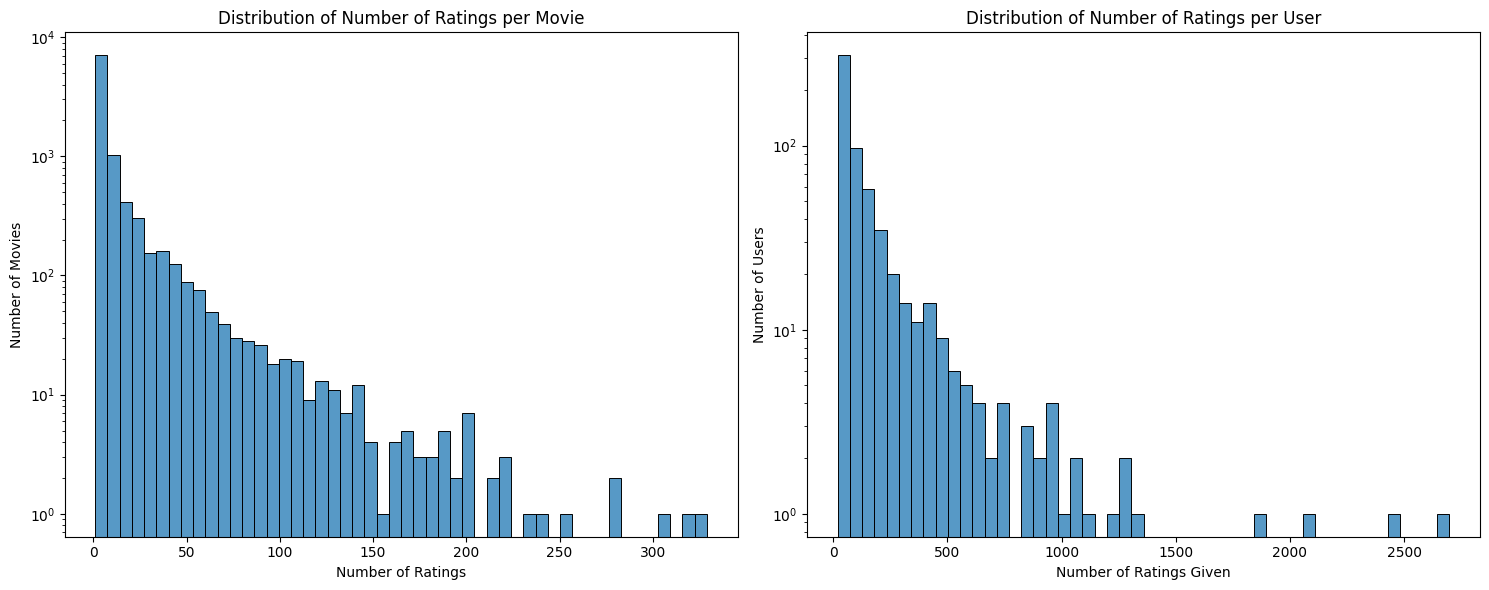

In [9]:
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
sns.histplot(movie_rating_counts, bins=50)
plt.title('Distribution of Number of Ratings per Movie')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Movies')
plt.yscale('log')

plt.subplot(1, 2, 2)
sns.histplot(user_rating_counts, bins=50)
plt.title('Distribution of Number of Ratings per User')
plt.xlabel('Number of Ratings Given')
plt.ylabel('Number of Users')
plt.yscale('log')
plt.tight_layout()
plt.show()

### Binarize ratings

For a Naive Bayes approach, we need to convert continuous ratings into discrete categories, such as 'liked' or 'not liked'. We wll consider a rating of 4.0 or higher as 'liked' (represented by 1), and anything below 4.0 as 'not liked' (represented by 0).

In [10]:
rating_pivot = rating.pivot_table(index='movieId', columns='userId', values='rating').fillna(0)
print('Shape of ratings pivot table:', rating_pivot.shape)
print(rating_pivot.head())

Shape of ratings pivot table: (9724, 610)
userId   1    2    3    4    5    6    7    8    9    10   ...  601  602  603  \
movieId                                                    ...                  
1        4.0  0.0  0.0  0.0  4.0  0.0  4.5  0.0  0.0  0.0  ...  4.0  0.0  4.0   
2        0.0  0.0  0.0  0.0  0.0  4.0  0.0  4.0  0.0  0.0  ...  0.0  4.0  0.0   
3        4.0  0.0  0.0  0.0  0.0  5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
4        0.0  0.0  0.0  0.0  0.0  3.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
5        0.0  0.0  0.0  0.0  0.0  5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

userId   604  605  606  607  608  609  610  
movieId                                     
1        3.0  4.0  2.5  4.0  2.5  3.0  5.0  
2        5.0  3.5  0.0  0.0  2.0  0.0  0.0  
3        0.0  0.0  0.0  0.0  2.0  0.0  0.0  
4        0.0  0.0  0.0  0.0  0.0  0.0  0.0  
5        3.0  0.0  0.0  0.0  0.0  0.0  0.0  

[5 rows x 610 columns]


In [11]:
like_th = 4.0
liked_df = (rating_pivot >= like_th).astype(int)

print('Shape of liked_df:', liked_df.shape)
display(liked_df.head())

Shape of liked_df: (9724, 610)


userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,1,0,0,0,1,0,1,0,0,0,...,1,0,1,0,1,0,1,0,0,1
2,0,0,0,0,0,1,0,1,0,0,...,0,1,0,1,0,0,0,0,0,0
3,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Naive Bayes Recommendation for multiple liked movies

This function will calculate a recommendation score for each unrated movie `A`, given a user's set of liked movies `B_1, ..., B_n`. The score will be proportional to:

$Score(A) \propto P(\text{like A}) \cdot \prod_{i=1}^{n} P(\text{liked } B_i | \text{like A})$

Where:
- $P(\text{like A})$ is the prior probability of liking Movie A.
- $P(\text{liked } B_i | \text{like A})$ is the conditional probability of liking Movie $B_i$ given that Movie A was liked.

Laplace smoothing will be applied to probabilities to handle cases where counts might be zero, preventing zero-probability issues. Uses log-probabilities to avoid numerical underflow.

In [14]:
def _get_user_liked_movies(train_movies, liked_data, last_n):
    """
    Retrieves the last_n liked movies from the training set for a user.
    """
    user_liked_movie_ids_for_model = train_movies[::-1][:last_n]
    user_liked_movie_ids_for_model = np.intersect1d(user_liked_movie_ids_for_model, liked_data.index.unique())
    return user_liked_movie_ids_for_model

def _get_candidate_movie_ids(train_movies, test_movies, all_movie_ids_in_liked_data):
    """
    Identifies candidate movies for recommendation.
    """
    candidate_movie_ids_set = np.setdiff1d(all_movie_ids_in_liked_data, train_movies)
    candidate_movie_ids = np.union1d(candidate_movie_ids_set, test_movies)
    candidate_movie_ids = np.intersect1d(candidate_movie_ids, all_movie_ids_in_liked_data)
    return candidate_movie_ids

def _calculate_prior_probabilities(L_A, num_users, laplace_smoothing):
    """
    Calculates the log prior probabilities P(like A) for candidate movies.
    """
    num_liked_A_total_series = L_A.sum(axis=1)
    log_P_A_priors = np.log((num_liked_A_total_series + laplace_smoothing) / (num_users + 2 * laplace_smoothing))
    return log_P_A_priors

def _calculate_conditional_probabilities(L_A, L_B, num_liked_A_total_series, laplace_smoothing):
    """
    Calculates the log conditional probabilities P(liked Bi | like A).
    """
    intersection_matrix = L_A.dot(L_B.T)
    numerator = intersection_matrix + laplace_smoothing
    denominator = num_liked_A_total_series + (2 * laplace_smoothing)
    P_Bi_given_A_matrix = numerator.divide(denominator, axis=0)
    log_P_Bi_given_A_matrix = np.log(P_Bi_given_A_matrix)
    return log_P_Bi_given_A_matrix

def _combine_probabilities_and_format_recommendations(log_scores_series, movies_df):
    """
    Formats the recommendation DataFrame based on the log scores.
    """
    recommended_movies_df = log_scores_series.reset_index()
    recommended_movies_df.columns = ['movieId', 'log_score']
    recommended_movies_df = recommended_movies_df.merge(movies_df[['movieId', 'title']], on='movieId', how='left')
    recommended_movies_df = recommended_movies_df[np.isfinite(recommended_movies_df['log_score'])]
    return recommended_movies_df

def get_naive_bayes_recommendations_train(user_id, train_movies, test_movies, liked_data, movies_df, last_n=10, laplace_smoothing=1):
    """
    Generates Naive Bayes-like recommendations for a given user based on their liked movies.
    The score returned is a log-score.

    Args:
        user_id (int): The ID of the user for whom to generate recommendations.
        train_movies (list): List of movie IDs to use for training.
        test_movies (list): List of movie IDs to use for testing.
        liked_data (pd.DataFrame): DataFrame with binarized 'liked' status (1 for liked, 0 for not liked/unrated).
        movies_df (pd.DataFrame): Original movies DataFrame to get titles.
        last_n (int): The number of last n liked movies - B1, ..., Bn to consider.
        laplace_smoothing (float): Smoothing parameter to avoid zero probabilities.

    Returns:
        tuple: (pd.DataFrame of recommended movies, str message).
    """
    num_users = liked_data.shape[1] - 1
    all_movie_ids_in_liked_data = liked_data.index.unique()

    user_liked_movie_ids_for_model = _get_user_liked_movies(train_movies, liked_data, last_n)

    if len(user_liked_movie_ids_for_model) == 0:
        return None, f"User {user_id} has not liked any movies yet in the training set. Cannot generate recommendations."

    candidate_movie_ids = _get_candidate_movie_ids(train_movies, test_movies, all_movie_ids_in_liked_data)

    if len(candidate_movie_ids) == 0:
        return None, f"No valid candidate movies to recommend for user {user_id}."

    liked_data = liked_data.drop(columns=[user_id])
    L_A = liked_data.loc[candidate_movie_ids]
    L_B = liked_data.loc[user_liked_movie_ids_for_model]

    log_P_A_priors = _calculate_prior_probabilities(L_A, num_users, laplace_smoothing)
    log_P_Bi_given_A_matrix = _calculate_conditional_probabilities(L_A, L_B, L_A.sum(axis=1), laplace_smoothing)

    sum_log_P_Bi_given_A_series = log_P_Bi_given_A_matrix.sum(axis=1)
    log_scores_series = log_P_A_priors + sum_log_P_Bi_given_A_series

    recommended_movies_df = _combine_probabilities_and_format_recommendations(log_scores_series, movies_df)

    if not recommended_movies_df.empty:
        return recommended_movies_df.sort_values(by='log_score', ascending=False), None
    else:
        return None, f"Could not generate recommendations for user {user_id}."


### Evaluating Naive Bayes Rrcommendations with precision and recall k

Precision k tells us, out of the top k movies we recommended, how many of them the user actually liked.

Recall k tells us, out of the test movies liked by the user, how many were recommended in the top k movies.

In [46]:
def calculate_precision_k(recommendations_df, test_movies, k=10):
    """
    Calculates Precision k for a given user's recommendations.
    """
    top_k_recommended_movie_ids = recommendations_df['movieId'].head(k).tolist()

    user_actual_liked_movies = test_movies

    hits = 0
    for movie_id in top_k_recommended_movie_ids:
        if movie_id in user_actual_liked_movies:
            hits += 1

    hit_rate = 1 if hits > 0 else 0

    return hit_rate, hits / k

def calculate_recall_k(recommendations_df, test_movies, k=10):
    """
    Calculates Recall k for a given user's recommendations.
    """
    top_k_recommended_movie_ids = recommendations_df['movieId'].head(k).tolist()

    user_actual_liked_movies = test_movies

    hits = 0
    for movie_id in user_actual_liked_movies:
        if movie_id in top_k_recommended_movie_ids:
            hits += 1

    return hits / len(user_actual_liked_movies)

Get all users with at least 200 ratings and apply Leave One User Out Cross Validation.

We chose 200 to make sure the test set has enough movies.

In [66]:
n = 200
users_with_at_least_n_ratings = rating['userId'].value_counts()
users_with_at_least_n_ratings = users_with_at_least_n_ratings[users_with_at_least_n_ratings >= n].index.tolist()

print(f"Number of users with at least {n} ratings: {len(users_with_at_least_n_ratings)}")
print(f"First 10 user IDs with at least {n} ratings:")
print(users_with_at_least_n_ratings[:10])

Number of users with at least 200 ratings: 134
First 10 user IDs with at least 200 ratings:
[414, 599, 474, 448, 274, 610, 68, 380, 606, 288]


Now we go over each user, sort its liked movies by most recently liked (by timestamp), and divide its liked movies to train and test.

We focus on it's top 200 liked movies to make the performance metrics comparable between users.

Then, performance metrics are calculated up to `k=200` top recommended movies.

In [67]:
all_prec = []
all_rec = []
all_hit_rates = []
for user_id in users_with_at_least_n_ratings:
  user_ratings = rating[rating['userId'] == user_id]
  user_liked_movie_ids = user_ratings[user_ratings['rating'] >= like_th]
  user_liked_movie_ids = user_liked_movie_ids.sort_values(by='timestamp', ascending=False)['movieId'].unique()
  user_liked_movie_ids = user_liked_movie_ids[::-1]
  trainMovies, testMovies = train_test_split(user_liked_movie_ids, shuffle=False, test_size=0.2, random_state=42)
  recommendations_df, message = get_naive_bayes_recommendations_train(user_id=user_id, train_movies=trainMovies, test_movies=testMovies, \
                                                                    liked_data=liked_df, movies_df=movies, last_n=2)
  if message:
    print(message)
    continue

  prec=[]
  rec=[]
  hit_rates_user = []
  for k in range(1,200):
    hit_rate, pr = calculate_precision_k(recommendations_df, testMovies, k=k)
    prec.append(pr)
    hit_rates_user.append(hit_rate)
    rec.append(calculate_recall_k(recommendations_df, testMovies, k=k))

  all_prec.append(prec)
  all_rec.append(rec)
  all_hit_rates.append(hit_rates_user)

Calculate the average precision and recall for every k across all users

In [68]:
precisions_array = np.array(all_prec)
recalls_array = np.array(all_rec)
hit_rates_array = np.array(all_hit_rates)
average_prec_per_k = np.mean(precisions_array, axis=0)
average_rec_per_k = np.mean(recalls_array, axis=0)
average_hit_rates_per_k = np.mean(hit_rates_array, axis=0)

denominator = average_prec_per_k + average_rec_per_k
average_f1_per_k = np.divide(2 * average_prec_per_k * average_rec_per_k, denominator, out=np.zeros_like(denominator), where=denominator!=0)

Plot the precision and recall

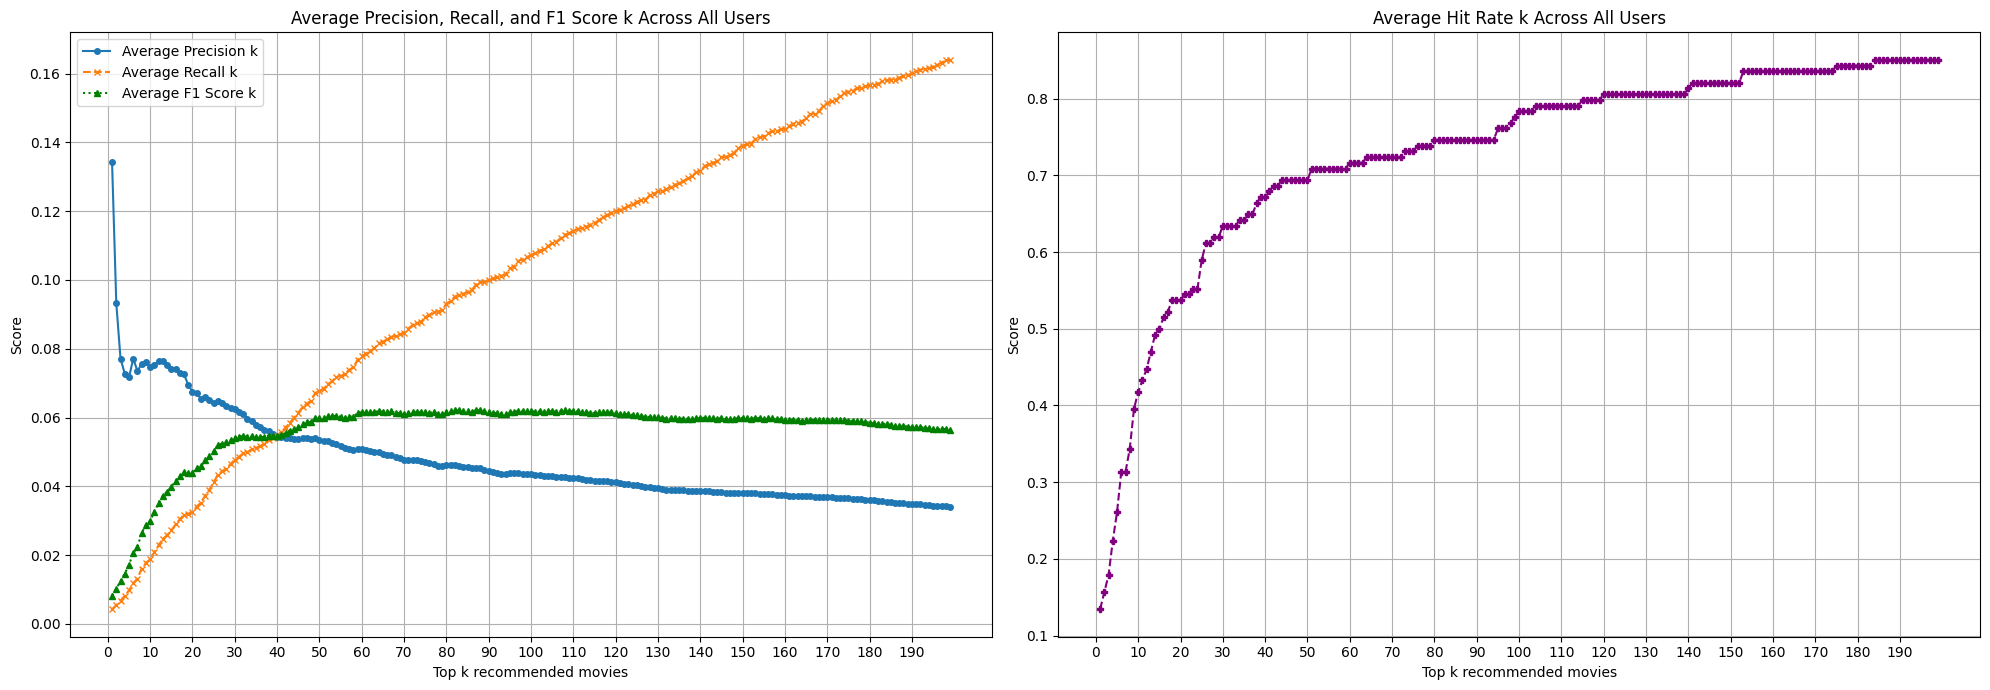

In [71]:
k_values = range(1, len(average_prec_per_k) + 1)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

axes[0].plot(k_values, average_prec_per_k, label='Average Precision k', marker='o', linestyle='-', markersize=4)
axes[0].plot(k_values, average_rec_per_k, label='Average Recall k', marker='x', linestyle='--', markersize=4)
axes[0].plot(k_values, average_f1_per_k, label='Average F1 Score k', marker='^', linestyle=':', markersize=4, color='green')
axes[0].set_title('Average Precision, Recall, and F1 Score k Across All Users')
axes[0].set_xlabel('Top k recommended movies')
axes[0].set_ylabel('Score')
axes[0].grid(True)
axes[0].set_xticks(np.arange(0, len(average_prec_per_k) + 1, 10))
axes[0].legend()

axes[1].plot(k_values, average_hit_rates_per_k, label='Average Hit Rate k', marker='P', linestyle='--', markersize=4, color='purple')
axes[1].set_title('Average Hit Rate k Across All Users')
axes[1].set_xlabel('Top k recommended movies')
axes[1].set_ylabel('Score')
axes[1].grid(True)
axes[1].set_xticks(np.arange(0, len(average_prec_per_k) + 1, 10))

plt.tight_layout()
plt.show()

### The figure displays the average Hit rate, Precision, Recall and F1 score k for the Naive Bayes recommendation system across 134 users with at least 200 movie ratings (last n = 2).

Precision k - This metric indicates, out of the top k movies we recommended, what proportion the user actually liked. As k increases, the avrage precision k decreases as expected (harder to maintain a high proportion of liked movies).

Recall k - This metric indicates, out of all the movies a user liked, what proportion were included in the top k movies. A k increases, the average recall k increases, as expected (capturing more liked movies).

F1 Score k - A higher F1 score indicates a better balance between precision and recall, meaning the model is both precise in its recommendations and comprehensive in recalling liked movies. It looks like that for `k=20` we achieve a sufficient balance between precision and recall, and in the number of recommended movies.

Hit rate k - a measure that captures at least one liked movie in the test set in the the top k recommended movies. For `k=20`, the hit rate is about 55%.

Note - there is a weakness in the number of last n liked movies, the higher this number the worse are the results since we will have less users with the same preferences as the current tested user.